# HW3 sentiment classification

Train three uncased BERT specialists with cleaned tweets. The validation set selects the voting rule. Report held-out and pooled scores after selection.

In [1]:
%%bash
set -e
cd /content

if [ -d Intro_to_AI_HW/.git ]; then
    git -C Intro_to_AI_HW pull --ff-only origin main
else
    git clone --branch main https://github.com/billlllllllly/Intro_to_AI_HW.git
fi

cd Intro_to_AI_HW/IAI_HW3
pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 43.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 15.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 12.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 48.2 MB/s  0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1



Cloning into 'Intro_to_AI_HW'...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


The previous fold-bagged run reported cross-calibrated OOF macro-F1 0.8830 and calibrated held-out test macro-F1 0.8690 (8,105 development and 895 test tweets). The next cell computes pooled macro-F1 on the same validation and test rows used for the specialist comparison when the original checkpoints are available.

In [2]:
%cd /content/Intro_to_AI_HW/IAI_HW3
from baseline_evaluation import baseline_score
baseline = baseline_score("/content/hw3_fold_checkpoints")


/content/Intro_to_AI_HW/IAI_HW3
Exact pooled baseline unavailable: previous fold checkpoints are missing.


In [3]:
import re
import pandas as pd

tweets = pd.read_csv("dataset/dataset.csv", keep_default_na=False)["text"]
patterns = {"emoticon": r"(?<!\w)(?:[:=;]-?[()\[\]DP/]|<3|\^_?\^|-_-)(?!\w)",
            "hashtag": r"#\w+", "elongated": r"([A-Za-z])\1{2,}", "HTML entity": r"&\w+;"}
for name, pattern in patterns.items():
    count = tweets.map(re.compile(pattern).search).notna().sum()
    print(f"{name}: {count}/{len(tweets)} ({count/len(tweets):.2%})")


emoticon: 178/9000 (1.98%)
hashtag: 1564/9000 (17.38%)
elongated: 56/9000 (0.62%)
HTML entity: 475/9000 (5.28%)


In [4]:
%cd /content/Intro_to_AI_HW/IAI_HW3
import torch
from main import run

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Colab before training.")

predictions, histories = run(
    ensemble=True, epochs=3, checkpoint_dir="/content/hw3_clean_specialists",
    review_path="/content/neutral_errors.csv", tune_neutral=True,
    sweep_path="/content/voting_sweep.csv",
)
if baseline is not None:
    print(f"Pooled macro-F1 change: {predictions.attrs['pooled_macro_f1'] - baseline:+.6f}")


/content/Intro_to_AI_HW/IAI_HW3
Removed nearly empty training posts by class: {'negative': 0, 'neutral': 0, 'positive': 0}
Device: cuda | train: 7200 | validation: 905 | test: 895


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Training CNN head | encoder LR 2e-05 | head LR 0.0002 | schedule linear | seed 42 | specialist negative


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Epoch 1/3 | train loss 0.3882, macro-F1 0.7599 | val loss 0.2488, macro-F1 0.8578
Epoch 2/3 | train loss 0.1741, macro-F1 0.9139 | val loss 0.2313, macro-F1 0.8825
Epoch 3/3 | train loss 0.1122, macro-F1 0.9582 | val loss 0.2544, macro-F1 0.8716
Best validation macro-F1 0.8825 at epoch 2.
Training MLP head | encoder LR 2e-05 | head LR 0.0002 | schedule linear | seed 43 | specialist neutral
Epoch 1/3 | train loss 0.5481, macro-F1 0.7390 | val loss 0.3212, macro-F1 0.8879
Epoch 2/3 | train loss 0.2715, macro-F1 0.9064 | val loss 0.2829, macro-F1 0.8883
Epoch 3/3 | train loss 0.2003, macro-F1 0.9416 | val loss 0.3017, macro-F1 0.8948
Best validation macro-F1 0.8948 at epoch 3.
Training MLP head | encoder LR 2e-05 | head LR 0.0002 | schedule linear | seed 44 | specialist positive
Epoch 1/3 | train loss 0.5343, macro-F1 0.7331 | val loss 0.3644, macro-F1 0.8749
Epoch 2/3 | train loss 0.2662, macro-F1 0.9018 | val loss 0.3018, macro-F1 0.8828
Epoch 3/3 | train loss 0.2011, macro-F1 0.9442 | 

In [5]:
import pandas as pd

errors = pd.read_csv('/content/neutral_errors.csv')
display(errors.groupby(['label', 'ensemble']).size().rename('count').to_frame())
display(errors.groupby('label', group_keys=False).head(10))

,,count
label,ensemble,
negative,neutral,16
neutral,negative,21


,id,text,label,negative_cnn,neutral_mlp,positive_mlp,ensemble
0,38,@AmericanAir work would be much better with my...,negative,positive,positive,neutral,neutral
1,274,@USAirways @rylietolbert15 wow you wouldn't say,negative,neutral,neutral,neutral,neutral
2,322,@jetblue the man sitting next 2 me at the term...,neutral,negative,neutral,neutral,negative
3,385,@SouthwestAir i cant look up my confirmation n...,neutral,negative,negative,negative,negative
4,879,@SouthwestAir still haven't been able to get t...,neutral,negative,negative,negative,negative
5,1498,@JetBlue I usually do-but I didn't make the Fl...,neutral,negative,neutral,negative,negative
6,1893,@united there are at least 3 of us on UA1564 a...,neutral,negative,negative,negative,negative
7,1972,@AmericanAir You're right. Someone is up to so...,neutral,negative,neutral,negative,negative
8,2019,@AmericanAir my flight got Cancelled Flightled...,neutral,negative,negative,negative,negative
9,2239,@SouthwestAir can i have my bags back ding!!,negative,neutral,neutral,neutral,neutral


In [6]:
from google.colab import files

output_path = "/content/predictions.csv"
predictions.to_csv(output_path, index=False)
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

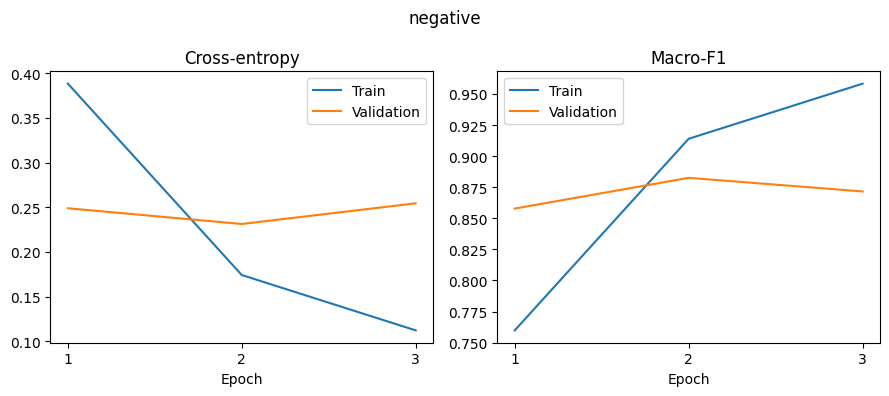

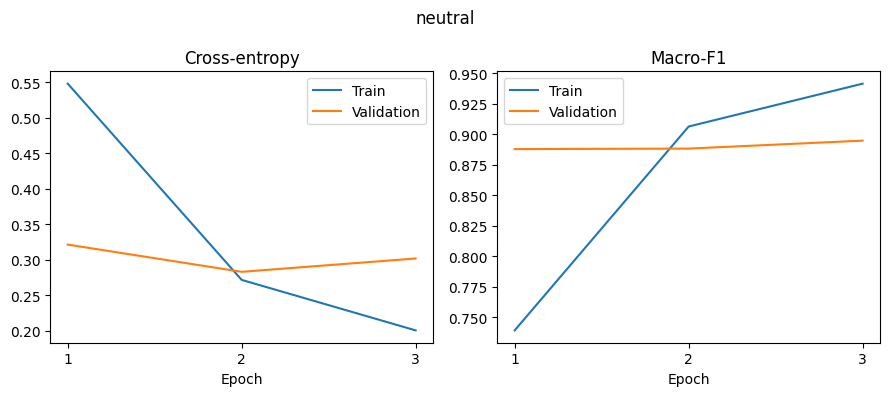

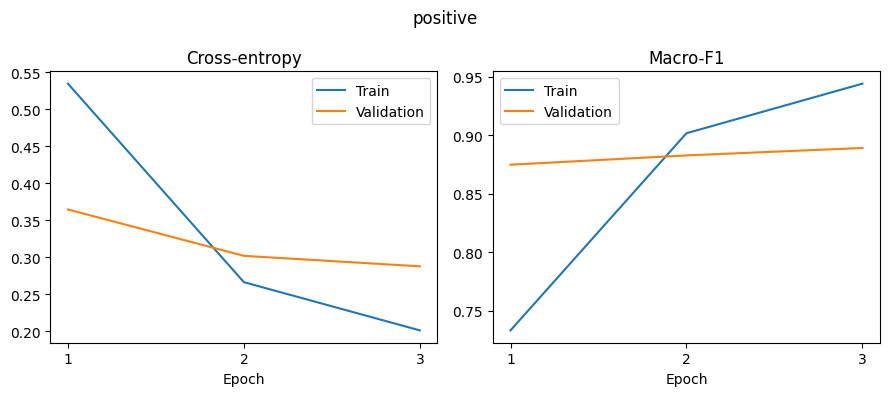

In [7]:
import matplotlib.pyplot as plt

for name, history in histories.items():
    epochs = range(1, len(history) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(9, 4))
    figure.suptitle(name)
    for index, title in enumerate(("Cross-entropy", "Macro-F1")):
        axes[index].plot(epochs, [train[index] for train, _ in history], label="Train")
        axes[index].plot(epochs, [val[index] for _, val in history], label="Validation")
        axes[index].set(xlabel="Epoch", title=title, xticks=list(epochs))
        axes[index].legend()
    figure.tight_layout()
    plt.show()